### Attempt to Forecast
Regressing signed_dollar_imbalance / session_dollar_imbalance.
Achieves suprising results! IC of 0.131 on minutely returns.
Different modeling approaches will be tried. For now, OLS or RLM.

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[2] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

with open("../../../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
START = "2025-06-02"
END = "2026-06-02"
DATASET = "XNAS.ITCH"

# Imbalance
df_imbalance = adapter.scan_data(
    tickers=UNIVERSE,
    start_date=START,
    end_date=END,
    dataset=DATASET,
    schema="imbalance"
)
df_imbalance = (
    df_imbalance
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .sort('ts_event')
)

# trades with the bbo
df_trades = adapter.scan_data(
    tickers=UNIVERSE,
    start_date=START,
    end_date=END,
    dataset=DATASET,
    schema="tbbo"
)
df_trades = (
    df_trades
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .sort('ts_event')
)

# statistics (for the official closing auction price)
df_stats = adapter.scan_data(
    tickers=UNIVERSE,
    start_date=START,
    end_date=END,
    dataset=DATASET,
    schema="statistics"
)
df_stats = (
    df_stats
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col("stat_type") == 11)
    .sort("ts_event")
)


CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 59acd1f31c5cb651598f2b52e55c5b57.parquet
[GenericAdapter] scan_parquet: ae6e2e353449ba87c7db99ba2b04787b.parquet
[GenericAdapter] scan_parquet: 5ad4fa3280634d57059736634fa2bfe8.parquet


In [2]:
# daily volume before the final 10mins, by date and symbol
session_dollar_volume = (df_trades
                         .with_columns(pl.col("ts_event").dt.date().alias("date"))
                         .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(15,50)))
                         .group_by(["date", "symbol"])
                         .agg(
                             (pl.col('size') * pl.col("price")).sum()
                             )
                        ).rename({"size": "session_dollar_volume"}).sort("date")

# official closing auction price, by date and symbol
auction = (
    df_stats
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        (pl.col("price") * pl.col("quantity")).alias("auction_dollars")
    )
    .select("date", "symbol", "price", "auction_dollars")
    .rename({"price": "auction_price"})
)

# close prices 15:50:00 - 16:00:00 (upper bound exclusive so the only
# 16:00:00 row is the synthetic auction bar built below)
bars = (
    df_trades
    .filter(
        (pl.col("ts_event").dt.time() >= pl.time(15,50,00))
        & (pl.col("ts_event").dt.time() < pl.time(16,00,00))
    )
    .group_by_dynamic(
        index_column="ts_event",
        every="1m",
        group_by="symbol"
    )
    .agg(
        pl.col(["price"]).last().alias("close")
    )
)

# auction (stat_type==11) as a synthetic 16:00:00 bar, same schema as `bars`
# (column order must match `bars`: symbol, ts_event, close)
auction_bars = (
    df_stats
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"])
    .agg(pl.col("price").last().alias("close"))     # official close price
    .with_columns(
        pl.col("date").dt.combine(pl.time(16, 0, 0))
          .dt.replace_time_zone("America/New_York")
          .dt.cast_time_unit("ns")          # match `bars` (ns) so concat schemas align
          .alias("ts_event")
    )
    .select(["symbol", "ts_event", "close"])
)

# per-minute closes plus the 16:00:00 auction print
all_bars = pl.concat([bars, auction_bars], how="vertical")

# imbalance messages by date and symbol from 15:50:00 - 16:00:00
# on a minutely basis, last message each minute.
imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time() >= pl.time(15,50))
    .group_by_dynamic(
        index_column="ts_event",
        every="1m",
        group_by="symbol"
    )
    .agg(
        pl.col(["side", "total_imbalance_qty"]).last()
    )
)

In [3]:
data = (
    all_bars
    .join(imb_print, on=["ts_event", "symbol"], how="left")   # 16:00 auction rows survive
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .join(session_dollar_volume, on=["date", "symbol"], how="left")
    .sort(["symbol", "ts_event"])               # required before shift/pct_change in a window
    .with_columns(
        (pl.col("total_imbalance_qty") * pl.col("close")).alias("signed_dollar_imbalance"),
    )
    .with_columns(
        # minute-over-minute return, reset at each new day so the
        # 16:00 -> next 15:50 jump is null, not a bogus overnight return.
        # At 16:00 this is the 15:59 -> auction "return to close".
        pl.col("close").pct_change().over(["symbol", "date"]).alias("ret_1m"),

        # signed imbalance as a fraction of pre-15:50 session $ volume
        # (null at the 16:00 auction row, which has no imbalance message)
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .otherwise(0)
            * (pl.col("signed_dollar_imbalance") / pl.col("session_dollar_volume"))
        ).fill_null(strategy="forward").over(["date", "symbol"]).alias("qty_signal"),
        pl.col("signed_dollar_imbalance").fill_null(strategy="forward").over(["date","symbol"])
    )
    .select(["date", "ts_event", "symbol", "close", "ret_1m", "signed_dollar_imbalance", "qty_signal"])
    .sort(["symbol", "ts_event"])
    .drop_nulls()
    .collect(engine="streaming")
)
data

date,ts_event,symbol,close,ret_1m,signed_dollar_imbalance,qty_signal
date,"datetime[ns, America/New_York]",cat,f64,f64,f64,f64
2025-06-02,2025-06-02 15:51:00 EDT,"""AAL""",11.365,0.000881,6.2715e6,0.148165
2025-06-02,2025-06-02 15:52:00 EDT,"""AAL""",11.355,-0.00088,6.6225e6,0.156459
2025-06-02,2025-06-02 15:53:00 EDT,"""AAL""",11.365,0.000881,6.6201e6,0.156401
2025-06-02,2025-06-02 15:54:00 EDT,"""AAL""",11.365,0.0,7.391796e6,0.174633
2025-06-02,2025-06-02 15:55:00 EDT,"""AAL""",11.375,0.00088,5683723.5,0.134279
…,…,…,…,…,…,…
2026-06-01,2026-06-01 15:56:00 EDT,"""ZYME""",24.595,-0.00061,56420.93,-0.033578
2026-06-01,2026-06-01 15:57:00 EDT,"""ZYME""",24.585,-0.000407,68100.45,-0.040529
2026-06-01,2026-06-01 15:58:00 EDT,"""ZYME""",24.57,-0.00061,0.0,0.0


In [4]:
import statsmodels.api as sm
study_data = (
    data
    .filter(pl.col("signed_dollar_imbalance") >= 500_000)
)
X = sm.add_constant(study_data['qty_signal'].clip(-1,1).to_numpy())
y = (study_data['ret_1m']).to_numpy()

res = sm.OLS(y, X).fit()
# res = sm.RLM(y, X, M=sm.robust.norms.HuberT()).fit()

# print(res.summary())
print(f'beta_0   = {res.params[0]:+.5f}')
print(f'beta_qty_signal    = {res.params[1]:+.5f}')
print(f'R^2     = {res.rsquared:.4f}')
print(f't(beta_qty_signal) = {res.tvalues[1]:+.2f}')

beta_0   = +0.00001
beta_qty_signal    = +0.00087
R^2     = 0.0187
t(beta_qty_signal) = +135.92


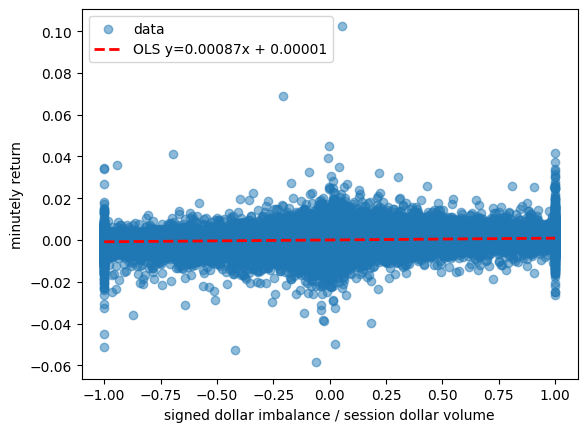

In [5]:
xs = np.linspace(np.min(X[:, 1]), np.max(X[:, 1])).clip()
plt.scatter(X[:, 1], y, alpha=0.5, label="data")
plt.plot(xs, res.params[1] * xs + res.params[0], label=f'OLS y={res.params[1]:,.5f}x + {res.params[0]:,.5f}',
         color='red', linestyle='--', linewidth=2)
plt.xlabel("signed dollar imbalance / session dollar volume")
plt.ylabel("minutely return")
plt.legend()
plt.show()

In [6]:
from scipy.stats import spearmanr

ic, pval = spearmanr(X[:, 1], y)
print(f"Spearman IC: {ic:,.3f} with p-value: {pval:,.3f}")

Spearman IC: 0.137 with p-value: 0.000
